In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

Dataset data_tolak_hb.csv merupakan dataset yang berisi jumlah pendonor darah yang ditolak akibat kadar hemoglobin (Hb) terlalu rendah atau terlalu tinggi. Dataset terdiri dari 243 data pengamatan dengan periode 1 Januari 2026 hingga 31 Agustus 2026. 

In [2]:
df = pd.read_csv('data_tolak_hb.csv')
df['TglPeriksa'] = pd.to_datetime(df['TglPeriksa'])
df = (
    df[['TglPeriksa', 'Jumlah_Pendonor']]
    .dropna()
    .sort_values('TglPeriksa')
    .set_index('TglPeriksa')
)

tanggal_lengkap = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq='D'
)
tanggal_hilang = tanggal_lengkap.difference(df.index)

print("Jumlah data:", len(df))
print("Tanggal awal:", df.index.min().date())
print("Tanggal akhir:", df.index.max().date())
print("Jumlah hari tanpa data:", len(tanggal_hilang))

Jumlah data: 243
Tanggal awal: 2026-01-01
Tanggal akhir: 2026-08-31
Jumlah hari tanpa data: 0


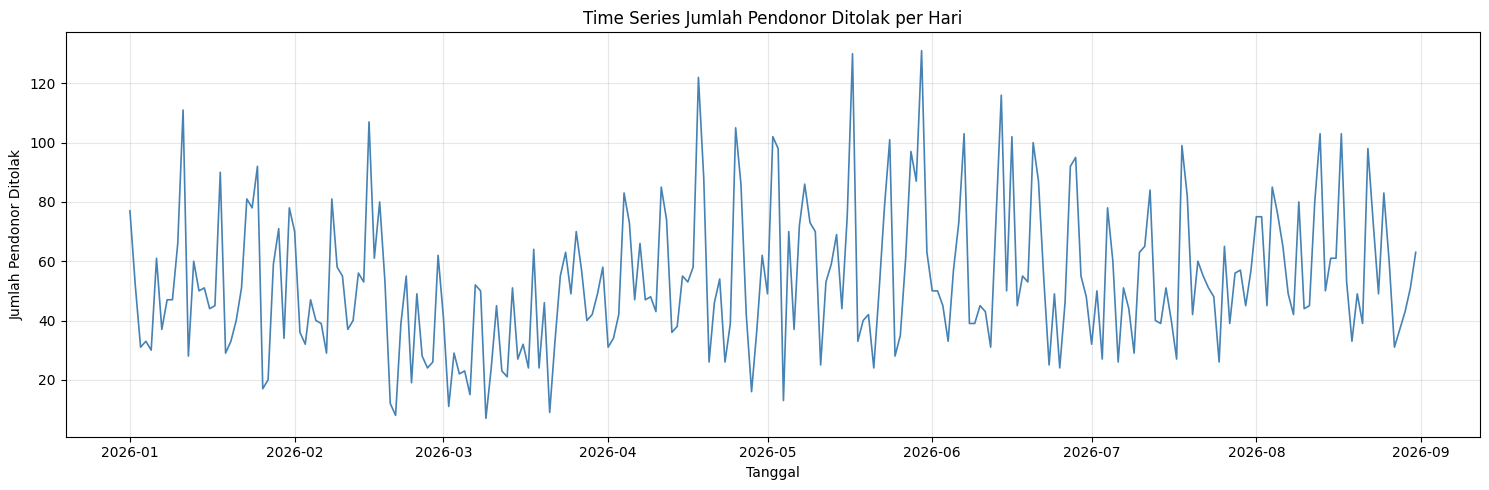

In [12]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['Jumlah_Pendonor'], color='steelblue', linewidth=1.2)

plt.title('Time Series Jumlah Pendonor Ditolak per Hari')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Pendonor Ditolak')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Analisis deret waktu menunjukkan adanya sedikit _tren_ menaik secara perlahan pada rata-rata nilai data dari awal tahun (Januari–Maret 2026) menuju pertengahan hingga akhir periode (April–Agustus 2026), di mana puncak-puncak nilai tertinggi lebih sering muncul di bulan April, Mei, Juni, dan Agustus dibandingkan bulan Januari.

Selain itu, terdapat pola naik-turun yang berulang sepanjang rentang waktu pengamatan yang mencerminkan adanya komponen _musiman_.

Data ini cenderung _tidak stasioner_ karena variasi atau sebaran nilainya tampak berfluktuasi cukup lebar di sekitar nilai rata-rata yang bergerak dan tidak konstan di satu garis rata-rata yang sama dari waktu ke waktu.

<Figure size 1500x500 with 0 Axes>

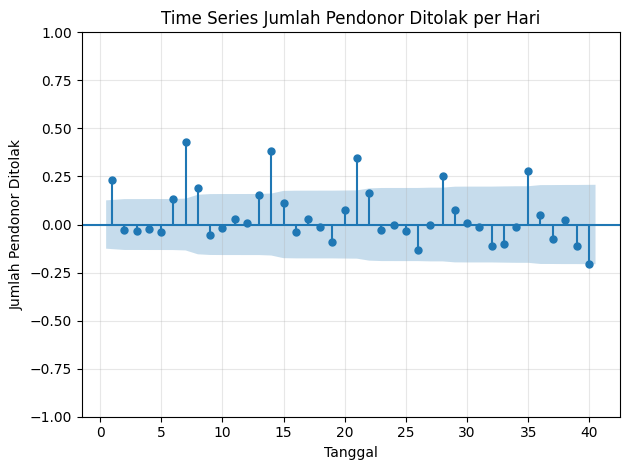

In [13]:
plt.figure(figsize=(15, 5))
plot_acf(df['Jumlah_Pendonor'], lags=min(40, len(df)//2 - 1),zero=False)
plt.title('Time Series Jumlah Pendonor Ditolak per Hari')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Pendonor Ditolak')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Berdasarkan plot Autocorrelation Function (ACF), terlihat adanya beberapa cut off pada lag tertentu yang keluar melewati batas area signifikansi biru. Hal ini mengindikasikan adanya pola musiman antara observasi saat ini dengan nilai pada periode sebelumnya.

In [14]:
result = adfuller(df['Jumlah_Pendonor'].dropna(), autolag='AIC')

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Lags Used:", result[2])
print("Observations:", result[3])
print("Critical Values:", result[4])

if result[1] < 0.05:
    print("\nKesimpulan: Data Stasioner")
else:
    print("\nKesimpulan: Data Non-Stasioner")

ADF Statistic: -1.8997722789968996
p-value: 0.3321682454514512
Lags Used: 13
Observations: 229
Critical Values: {'1%': np.float64(-3.4592326027153493), '5%': np.float64(-2.8742454699025872), '10%': np.float64(-2.5735414688888465)}

Kesimpulan: Data Non-Stasioner


Berdasarkan hasil uji statistik Augmented Dickey-Fuller (ADF) di mana nilai p-value tercatat sebesar $0.3321 > 0.05$ (dengan statistik ADF $-1.90$), yang membuktikan secara statistik bahwa data bersifat non-stasioner.

Karena data memiliki komponen tren, musiman, serta terbukti non-stasioner, maka model baseline yang paling tepat digunakan adalah **SARIMA** (Seasonal Autoregressive Integrated Moving Average). Model ini dipilih karena mampu menangani ketidakstasioneran melalui proses differencing.

Sebagai model komparatif, penelitian ini menggunakan **Random Forest** karena memiliki kemampuan yang baik dalam menangkap pola fluktuasi data deret waktu melalui pendekatan ensemble learning. Pemilihan Random Forest juga didasarkan pada jumlah data yang relatif terbatas, yaitu sebanyak 243 observasi harian, sehingga model ini dinilai sesuai untuk menghasilkan prediksi yang stabil dan memiliki risiko overfitting yang relatif terkendali.